# Pipeline audit
Quality cut and N sigma pipeline check

In [48]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

CATALOG_FITS = Path("/work/11161/kanyuni/ls6/quassiQ_project/QSO_iron/iron/QSO_cat_iron_cumulative_v0.fits")
CHI2_CSV = Path("/work/10579/prisha/ls6/desi_project/post_chi2_calc.csv")
FINAL_CSV = Path("/work/11161/kanyuni/ls6/quassiQ_project/quality_cut/final_subset.csv") # after filter_chi2.py
SNR_CSV = Path("/work/10579/prisha/ls6/desi_project/CLQ_cands_snr.csv")  # Selected sample before SNR ≥ 2.
NSIGMA_INPUT_CSV = FINAL_CSV
NSIGMA_DIR = Path("/work/10579/prisha/ls6/desi_project/nsigma_results") # Use the selected sample before SNR > 2 (~90k coadds).


RECON_DIR = Path("/work/10579/prisha/ls6/desi_project/reconstructions")
RECHECK_CHI2 = False  # Set True to recompute one example from its FITS file.

coadd_dir = Path("/work/10579/prisha/ls6/desi_project/output_coadds")

In [2]:
def read_csv(path):
    return pd.read_csv(path, dtype={"TARGETID": "string", "LASTNIGHT": "string"})


def target_ids(frame):
    return pd.Index(frame["TARGETID"].unique(), name="TARGETID")


removed_targets = {}


def count_cut(label, before, after):
    dropped = target_ids(before).difference(target_ids(after), sort=False)
    removed_targets[label] = dropped
    print(f"{label} | coadds: {len(before):,} → {len(after):,} ({len(before) - len(after):,} removed)")
    print(f"Targets: {before['TARGETID'].nunique():,} → {after['TARGETID'].nunique():,} ({len(dropped):,} removed)")


def dates(frame):
    night = frame["LASTNIGHT"].astype("string").str[:10].str.replace("-", "", regex=False)
    return pd.to_datetime(night, format="%Y%m%d")


def cadence(frame):
    nights = frame.assign(date=dates(frame)).groupby("TARGETID")["date"].agg(["min", "max", "count"])
    nights["span_days"] = (nights["max"] - nights["min"]).dt.days
    return nights

## 1. Raw catalog and redshift

In [3]:
from astropy.io import fits

with fits.open(CATALOG_FITS) as hdul:
    catalog = hdul[1].data
    raw = pd.DataFrame({
        "TARGETID": np.array(catalog["TARGETID"], dtype="int64"),
        "Z": catalog["Z"].astype(catalog["Z"].dtype.newbyteorder("=")),
        "ZWARN": np.array(catalog["ZWARN"], dtype="int64"),
        "COADD_FIBERSTATUS": np.array(catalog["COADD_FIBERSTATUS"], dtype="int64"),
        "LASTNIGHT": np.array(catalog["LASTNIGHT"], dtype="int64"),
    })
raw["TARGETID"] = raw["TARGETID"].astype("string")
print(f"{len(raw):,} coadds | {raw['TARGETID'].nunique():,} targets")

2,182,309 coadds | 1,650,736 targets


In [4]:
# # One redshift per target: the median of its finite raw coadd redshifts.
# target_z = raw.loc[np.isfinite(raw["Z"])].groupby("TARGETID")["Z"].median()
# print(f"Targets without a finite redshift: {raw['TARGETID'].nunique() - len(target_z):,}")

## 2. ZWARN and fiber status

In [5]:
zwarn_pass = raw.loc[raw["ZWARN"].eq(0)]
count_cut("ZWARN = 0", raw, zwarn_pass)
print(f"Targets with any rejected coadd: {raw.loc[raw['ZWARN'].ne(0), 'TARGETID'].nunique():,}")
removed_targets["ZWARN = 0"][:10]

ZWARN = 0 | coadds: 2,182,309 → 2,090,245 (92,064 removed)
Targets: 1,650,736 → 1,590,197 (60,539 removed)
Targets with any rejected coadd: 87,816


Index(['39628473202905021', '39628478454174522', '39628514831368530',
       '39628530245435964', '39628525132579383', '39628530237050948',
       '39628509701734757', '39628509714319481', '39628509701734873',
       '39628499358585119'],
      dtype='string', name='TARGETID')

In [6]:
quality_pass = zwarn_pass.loc[zwarn_pass["COADD_FIBERSTATUS"].eq(0)]
count_cut("COADD_FIBERSTATUS = 0", zwarn_pass, quality_pass)

COADD_FIBERSTATUS = 0 | coadds: 2,090,245 → 2,090,245 (0 removed)
Targets: 1,590,197 → 1,590,197 (0 removed)


## 3. Redshift membership

In [7]:
# Keep all quality-passing coadds of targets with at least half in range.
in_range = quality_pass["Z"].between(2.1, 3.5)
fraction_in_range = in_range.groupby(quality_pass["TARGETID"]).transform("mean")
redshift_pass = quality_pass.loc[fraction_in_range.ge(0.5)]
count_cut("At least half of coadds in 2.1–3.5", quality_pass, redshift_pass)

At least half of coadds in 2.1–3.5 | coadds: 2,090,245 → 802,381 (1,287,864 removed)
Targets: 1,590,197 → 447,153 (1,143,044 removed)


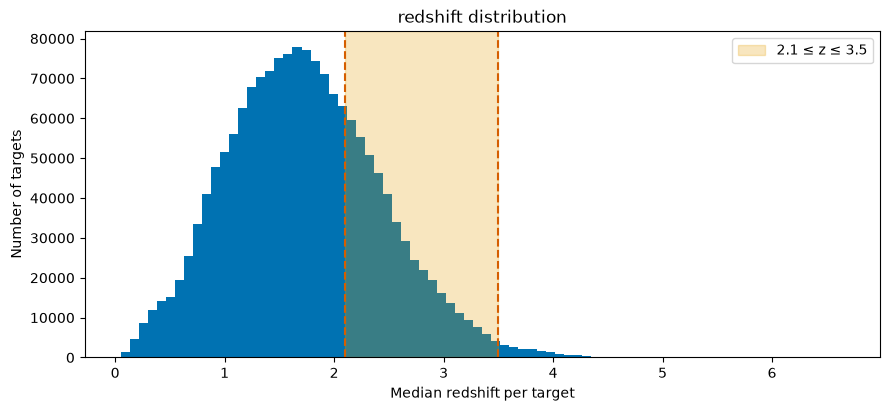

In [36]:
target_z = raw.groupby("TARGETID")["Z"].median()
target_z = target_z[np.isfinite(target_z)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(target_z, bins=80, color="#0072B2")
ax.axvspan(2.1, 3.5, color="#E69F00", alpha=0.25, label="2.1 ≤ z ≤ 3.5")
ax.axvline(2.1, color="#D55E00", linestyle="--")
ax.axvline(3.5, color="#D55E00", linestyle="--")
ax.set_xlabel("Median redshift per target")
ax.set_ylabel("Number of targets")
ax.legend()
fig.tight_layout()
ax.set_title("redshift distribution")
plt.show()

## 4. Repeated observations and time span

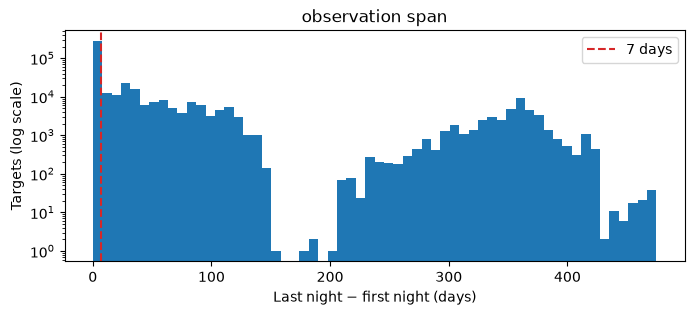

In [37]:
observation_span = cadence(redshift_pass)
%matplotlib inline
plt.figure(figsize=(8, 3))
plt.hist(observation_span["span_days"].dropna(), bins=60)
plt.axvline(7, color="tab:red", linestyle="--", label="7 days")
plt.yscale("log")
plt.xlabel("Last night − first night (days)")
plt.ylabel("Targets (log scale)")
plt.legend()
plt.title("observation span")
plt.show()

In [10]:
repeat_ids = observation_span.index[observation_span["count"].ge(2)]
repeat_pass = redshift_pass.loc[redshift_pass["TARGETID"].isin(repeat_ids)]
count_cut("At least 2 observations", redshift_pass, repeat_pass)

span_ids = observation_span.index[observation_span["span_days"].ge(7)]
quality_candidates = repeat_pass.loc[repeat_pass["TARGETID"].isin(span_ids)]
count_cut("Span ≥ 7 days", repeat_pass, quality_candidates)

At least 2 observations | coadds: 802,381 → 542,132 (260,249 removed)
Targets: 447,153 → 186,904 (260,249 removed)
Span ≥ 7 days | coadds: 542,132 → 505,848 (36,284 removed)
Targets: 186,904 → 170,648 (16,256 removed)


## 5. Selected sample and SNR

`calculate_snr.py` writes the median of flux × √IVAR across positive-IVAR pixels. The notebook reads those values and applies the slide’s SNR cut.

In [11]:
snr_scored = read_csv(SNR_CSV)
print(f"Selected sample: {len(snr_scored):,} coadds | {snr_scored['TARGETID'].nunique():,} targets")
omitted_at_sampling = target_ids(quality_candidates).difference(target_ids(snr_scored), sort=False)
unexpected_sample_ids = target_ids(snr_scored).difference(target_ids(quality_candidates), sort=False)
print(f"Quality-cut targets outside selected sample: {len(omitted_at_sampling):,}")
print(f"Selected targets absent from recomputed quality cut: {len(unexpected_sample_ids):,}")

Selected sample: 504,453 coadds | 170,148 targets
Quality-cut targets outside selected sample: 507
Selected targets absent from recomputed quality cut: 7


In [12]:
snr = snr_scored["MEDIAN_SNR"]
print(f"Coadds with missing or non-finite SNR: {(~np.isfinite(snr)).sum():,}")
snr_pass = snr_scored.loc[snr.ge(2)]
count_cut("Median SNR ≥ 2", snr_scored, snr_pass)

Coadds with missing or non-finite SNR: 419,394
Median SNR ≥ 2 | coadds: 504,453 → 40,456 (463,997 removed)
Targets: 170,148 → 13,477 (156,671 removed)


In [13]:
snr_cadence = cadence(snr_pass)
snr_repeat_ids = snr_cadence.index[snr_cadence["count"].ge(2)]
snr_repeat = snr_pass.loc[snr_pass["TARGETID"].isin(snr_repeat_ids)]
count_cut("SNR sample, at least 2 observations", snr_pass, snr_repeat)

snr_span_ids = snr_cadence.index[snr_cadence["span_days"].ge(7)]
snr_ready = snr_repeat.loc[snr_repeat["TARGETID"].isin(snr_span_ids)]
count_cut("SNR sample, span ≥ 7 days", snr_repeat, snr_ready)

SNR sample, at least 2 observations | coadds: 40,456 → 39,130 (1,326 removed)
Targets: 13,477 → 12,151 (1,326 removed)
SNR sample, span ≥ 7 days | coadds: 39,130 → 38,767 (363 removed)
Targets: 12,151 → 11,997 (154 removed)


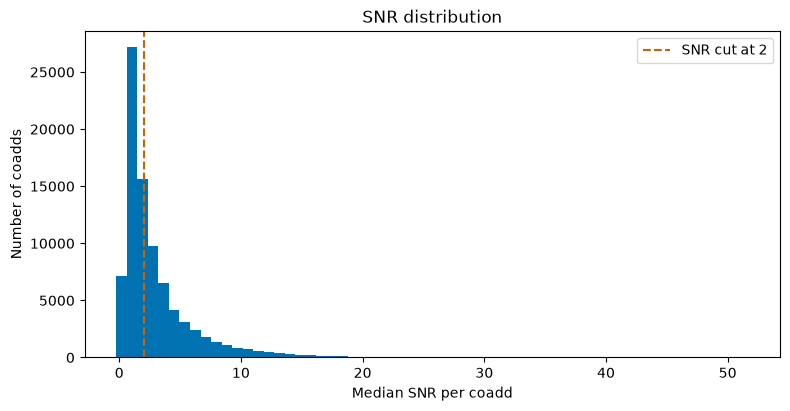

In [42]:
snr = pd.to_numeric(snr_scored["MEDIAN_SNR"], errors="coerce")
snr = snr[np.isfinite(snr)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(snr, bins=60, color="#0072B2")
ax.axvline(2, color="#D55E00", linestyle="--", label="SNR cut at 2")
ax.set(xlabel="Median SNR per coadd", ylabel="Number of coadds")
ax.legend()
fig.tight_layout()
ax.set_title("SNR distribution")
plt.show()

## 6. Reduced χ²

In [14]:
coadd_columns = ["TARGETID", "LASTNIGHT", "TILEID", "PETAL_LOC"]


def coadd_counts(frame):
    keys = frame[coadd_columns].copy()
    keys["LASTNIGHT"] = dates(keys).dt.strftime("%Y%m%d")
    return keys.value_counts(sort=False)


def compare_coadds(expected, saved):
    expected_counts = coadd_counts(expected)
    saved_counts = coadd_counts(saved)
    difference = expected_counts.subtract(saved_counts, fill_value=0)
    print(f"Expected coadds missing from CSV: {difference.clip(lower=0).sum():,.0f}")
    print(f"Extra coadds in CSV: {-difference.clip(upper=0).sum():,.0f}")
    return difference.loc[difference.ne(0)]


chi2 = read_csv(CHI2_CSV)
snr_chi2_mismatch = compare_coadds(snr_ready, chi2)
display(snr_chi2_mismatch.head(10))

Expected coadds missing from CSV: 0
Extra coadds in CSV: 0


Series([], Name: count, dtype: int64)

In [15]:
value = pd.to_numeric(chi2["REDUCED_CHI2"], errors="coerce")
valid_chi2 = np.isfinite(value) & value.ge(0)
passes_chi2 = valid_chi2 & value.le(1.4)

chi2_pass = chi2.loc[passes_chi2]
chi2_failed = chi2.loc[~passes_chi2]
chi2_high = chi2.loc[valid_chi2 & value.gt(1.4)]

print(f"Coadds above 1.4: {len(chi2_high):,} | missing or invalid χ²: {(~valid_chi2).sum():,}")
count_cut("Reduced χ² ≤ 1.4", chi2, chi2_pass)

Coadds above 1.4: 1,944 | missing or invalid χ²: 8
Reduced χ² ≤ 1.4 | coadds: 38,767 → 36,815 (1,952 removed)
Targets: 11,997 → 11,697 (300 removed)


In [16]:
chi2_cadence = cadence(chi2_pass)
chi2_repeat_ids = chi2_cadence.index[chi2_cadence["count"].ge(2)]
chi2_repeat = chi2_pass.loc[chi2_pass["TARGETID"].isin(chi2_repeat_ids)]
count_cut("χ² sample, at least 2 observations", chi2_pass, chi2_repeat)

chi2_span_ids = chi2_cadence.index[chi2_cadence["span_days"].ge(7)]
final_expected = chi2_repeat.loc[chi2_repeat["TARGETID"].isin(chi2_span_ids)]
count_cut("χ² sample, span ≥ 7 days", chi2_repeat, final_expected)

χ² sample, at least 2 observations | coadds: 36,815 → 36,559 (256 removed)
Targets: 11,697 → 11,441 (256 removed)
χ² sample, span ≥ 7 days | coadds: 36,559 → 36,511 (48 removed)
Targets: 11,441 → 11,420 (21 removed)


In [17]:
failed_ids = target_ids(chi2_failed)
all_coadds_pass = final_expected.loc[~final_expected["TARGETID"].isin(failed_ids)]
count_cut("Require every pre-cut coadd to pass χ²", final_expected, all_coadds_pass)

retained_with_high = chi2_high.loc[chi2_high["TARGETID"].isin(final_expected["TARGETID"])]
print(f"Currently retained targets with any χ² > 1.4: {retained_with_high['TARGETID'].nunique():,}")

coadds_by_target = pd.concat({
    "before χ²": chi2.groupby("TARGETID").size(),
    "after per-coadd χ²": chi2_pass.groupby("TARGETID").size(),
    "after χ² and cadence": final_expected.groupby("TARGETID").size(),
    "if every coadd must pass": all_coadds_pass.groupby("TARGETID").size(),
}, axis=1).fillna(0).astype(int)

chi2_differences = coadds_by_target.loc[
    coadds_by_target["before χ²"].ne(coadds_by_target["after per-coadd χ²"])
]
print(f"Targets with at least one rejected coadd: {len(chi2_differences):,}")
display(chi2_differences.head(10))

Require every pre-cut coadd to pass χ² | coadds: 36,511 → 35,463 (1,048 removed)
Targets: 11,420 → 11,096 (324 removed)
Currently retained targets with any χ² > 1.4: 319
Targets with at least one rejected coadd: 901


,before χ²,after per-coadd χ²,after χ² and cadence,if every coadd must pass
TARGETID,,,,
39627553517864399,2,1,0,0
39627607381118145,2,0,0,0
39627609117563176,2,0,0,0
39627613513187852,2,0,0,0
39627619351662262,2,1,0,0
39627619427162220,2,0,0,0
39627619477489892,2,1,0,0
39627619708177792,2,0,0,0
39627631330594211,3,2,0,0


### Check one χ² value

`calculate_chi2.py:50–65` resumes from an existing output CSV and skips rows with a recorded DOF. Line 82 uses only target and night for the reconstruction path.

In [18]:
# If this number is nonzero, inspect these keys in the reconstruction files.
chi2_keys = coadd_counts(chi2).reset_index(name="rows")
same_night = chi2_keys.loc[chi2_keys.duplicated(["TARGETID", "LASTNIGHT"], keep=False)]
print(f"Distinct coadd keys sharing a target/night reconstruction path: {len(same_night):,}")
display(same_night.head(10))

if RECHECK_CHI2:
    examples = final_high if not final_high.empty else chi2_high
    if examples.empty:
        examples = chi2_pass
    example = examples.head(1)
    tid = example["TARGETID"].iloc[0]
    night = dates(example).dt.strftime("%Y%m%d").iloc[0]
    recon_path = RECON_DIR / tid / night / f"recon_{tid}_{night}.fits"
    with fits.open(recon_path) as hdul:
        pixels = hdul[1].data
        original = pixels["ORIG_FLUX"]
        reconstructed = pixels["RECON_FLUX"]
        weights = pixels["UPDATED_WEIGHTS"]
        valid = (weights > 0) & np.isfinite(original) & np.isfinite(reconstructed)
        dof = valid.sum()
        recomputed = np.sum((original[valid] - reconstructed[valid])**2 * weights[valid]) / dof if dof else np.nan
    print(f"Target {tid}, night {night} | valid pixels: {dof:,}")
    print(f"Saved χ²: {example['REDUCED_CHI2'].iloc[0]} | recomputed χ²: {recomputed}")

Distinct coadd keys sharing a target/night reconstruction path: 73


,TARGETID,LASTNIGHT,TILEID,PETAL_LOC,rows
878,39627908964158333,20210407,148,7,1
879,39627908964158333,20210407,137,7,1
1133,39627908955767854,20210416,149,3,1
1134,39627908955767854,20210416,141,3,1
1651,39632946105157843,20210404,80889,6,1
1652,39632946105157843,20210404,80890,6,1
1709,39627890907681013,20210502,144,8,1
1710,39627890907681013,20210502,151,8,1
2689,39632956620278806,20210406,80897,5,1
2690,39632956620278806,20210406,80898,5,1


## 7. Nσ input checks

Use the CSVs from a completed `nsigma.py` run. The cells below follow the observations and candidates from that run.

In [19]:
with (NSIGMA_DIR / "run_info.json").open() as file:
    run_info = json.load(file)
settings = run_info["arguments"]
print("Input used in the Nσ run:", settings["input_csv"])
print("Input read by this notebook:", NSIGMA_INPUT_CSV)
print(f"Rest-frame bin width: {settings['rest_bin_width']:g} Å")
print(f"Line window: ±{settings['half_window_kms']:g} km/s | Nσ > {settings['threshold']:g}")

ns_input = read_csv(NSIGMA_INPUT_CSV)
ns_snr = ns_input.loc[np.isfinite(ns_input["MEDIAN_SNR"]) & ns_input["MEDIAN_SNR"].gt(2)].copy()
count_cut("Nσ input, median SNR > 2", ns_input, ns_snr)

Input used in the Nσ run: subset_cands.csv
Input read by this notebook: /work/11161/kanyuni/ls6/quassiQ_project/quality_cut/final_subset.csv
Rest-frame bin width: 2 Å
Line window: ±5000 km/s | Nσ > 3
Nσ input, median SNR > 2 | coadds: 36,511 → 36,511 (0 removed)
Targets: 11,420 → 11,420 (0 removed)


In [20]:
ns_snr["LASTNIGHT"] = dates(ns_snr).dt.strftime("%Y%m%d")
ns_unique = ns_snr.drop_duplicates(coadd_columns).sort_values(coadd_columns)
count_cut("Nσ input, one row per coadd key", ns_snr, ns_unique)

ns_cadence = cadence(ns_unique)
ns_repeat_ids = ns_cadence.index[ns_cadence["count"].ge(2)]
ns_repeat = ns_unique.loc[ns_unique["TARGETID"].isin(ns_repeat_ids)]
count_cut("Nσ input, at least 2 observations", ns_unique, ns_repeat)

ns_span_ids = ns_cadence.index[ns_cadence["span_days"].ge(7)]
ns_ready = ns_repeat.loc[ns_repeat["TARGETID"].isin(ns_span_ids)]
count_cut("Nσ input, span ≥ 7 days", ns_repeat, ns_ready)

Nσ input, one row per coadd key | coadds: 36,511 → 36,511 (0 removed)
Targets: 11,420 → 11,420 (0 removed)
Nσ input, at least 2 observations | coadds: 36,511 → 36,511 (0 removed)
Targets: 11,420 → 11,420 (0 removed)
Nσ input, span ≥ 7 days | coadds: 36,511 → 36,511 (0 removed)
Targets: 11,420 → 11,420 (0 removed)


In [21]:
shared_paths = same_night.groupby(["TARGETID", "LASTNIGHT"]).size()
print("Shared reconstruction paths:", len(shared_paths))
print("Unique targets affected:", same_night["TARGETID"].nunique())
display(shared_paths.sort_values(ascending=False).head(10))

Shared reconstruction paths: 34
Unique targets affected: 33


TARGETID           LASTNIGHT
39633499711341874  20210223     5
39633509194664945  20210223     3
39633505474317281  20210223     3
39632956632862141  20210406     2
39632956179875640  20210404     2
39632956393785865  20210410     2
                   20220402     2
39632956620278806  20210406     2
39632956624471846  20210406     2
39632971405198686  20210410     2
dtype: int64

In [22]:
# This shows that the lights of the same targets could come into different petals (so fibers) but doesn't affect chi2
tid = "39633505474317281"
night = "20210223"

rows = chi2.loc[
    chi2["TARGETID"].eq(tid) & dates(chi2).dt.strftime("%Y%m%d").eq(night)
]
display(rows[["TILEID", "PETAL_LOC", "REDUCED_CHI2", "DOF"]])

,TILEID,PETAL_LOC,REDUCED_CHI2,DOF
8549,80789,5,1.297879,4086.0
8550,80785,8,1.297879,4086.0
8551,80788,7,1.297879,4086.0


In [23]:
target_summary = read_csv(NSIGMA_DIR / "target_summary.csv")
print(f"Run cohort: {len(target_summary):,} targets, "
      f"{target_summary['N_OBSERVATIONS'].sum():,} coadds")

Run cohort: 11,997 targets, 38,767 coadds


### 8. Prepare spectra and form pairs

Correct the coadds for Galactic extinction, shift them by each target’s median redshift, rebin to a common rest-frame grid, and combine cameras. A comparison needs two prepared coadds with shared valid bins.

In [24]:
pair_keys = ["TARGETID", "OBS1", "OBS2"]
ns_losses = {}


def ns_step(label, before, after, pair_columns=None):
    dropped = target_ids(before).difference(target_ids(after), sort=False)
    ns_losses[label] = dropped
    print(f"{label} | targets: {before['TARGETID'].nunique():,} → {after['TARGETID'].nunique():,} ({len(dropped):,} removed)")
    if pair_columns:
        print(f"Pairs: {len(before[pair_columns].drop_duplicates()):,} → {len(after[pair_columns].drop_duplicates()):,}")
        print(f"Line × pair rows: {len(before):,} → {len(after):,}")


prepared = target_summary.loc[target_summary["N_LOADED"].ge(2)]
ns_step("At least two prepared coadds", target_summary, prepared)
print(f"Coadds that did not prepare: {(target_summary['N_OBSERVATIONS'] - target_summary['N_LOADED']).sum():,}")
errors = read_csv(NSIGMA_DIR / "errors.csv")
display(errors["STAGE"].value_counts())

At least two prepared coadds | targets: 11,997 → 11,997 (0 removed)
Coadds that did not prepare: 3


STAGE
read_or_prepare    3
Name: count, dtype: int64

In [25]:
compared = prepared.loc[prepared["N_PAIRS_COMPARED"].gt(0)]
ns_step("At least one usable comparison", prepared, compared)
print(f"Catalog pairs: {target_summary['N_PAIRS_CATALOG'].sum():,}")
print(f"Pairs with shared valid bins: {target_summary['N_PAIRS_COMPARED'].sum():,}")

At least one usable comparison | targets: 11,997 → 11,997 (0 removed)
Catalog pairs: 56,568
Pairs with shared valid bins: 56,549


### 9. Peak Nσ in each emission-line window

For each pair, compute |flux2 − flux1| / √(variance1 + variance2) per shared rebinned pixel. Keep a line × pair if its peak exceeds the run threshold. The peak uses the coadd flux before local continuum subtraction. The audit CSV starts at threshold crossings, so it cannot distinguish a below-threshold pair from one with no usable line window.

In [26]:
peak_pass = read_csv(NSIGMA_DIR / "nsigma_passed_line_metrics.csv")
ns_step("At least one line × pair above the Nσ threshold", compared, peak_pass)
print(f"Pairs above threshold: {len(peak_pass[pair_keys].drop_duplicates()):,}")
print(f"Line × pair rows above threshold: {len(peak_pass):,}")
display(peak_pass[pair_keys + ["LINE", "MAX_NSIGMA"]].head())

At least one line × pair above the Nσ threshold | targets: 11,997 → 11,195 (802 removed)
Pairs above threshold: 47,173
Line × pair rows above threshold: 125,154


,TARGETID,OBS1,OBS2,LINE,MAX_NSIGMA
0,39627553509478604,20210517_tile1586_petal9,20220604_tile7852_petal0,Lyalpha,4.580266
1,39627553509478604,20210517_tile1586_petal9,20220604_tile7852_petal0,CIV,3.828792
2,39627553509478488,20210517_tile1586_petal9,20220604_tile7852_petal0,Lyalpha,5.147229
3,39627553509478488,20210517_tile1586_petal9,20220604_tile7852_petal0,SiIV_OIV_blend,4.768830
4,39627553509478488,20210517_tile1586_petal9,20220604_tile7852_petal0,CIV,3.782223


### 10. Measure continuum-subtracted line flux

Fit a linear continuum in the sidebands for each coadd. Subtract it and integrate the flux across the line in both epochs. The ratio requires positive dim-epoch flux.

In [27]:
integrated = peak_pass.loc[peak_pass["F_DIM"].notna()]
ns_step("Both line fluxes measured", peak_pass, integrated, pair_keys)

ratio_ready = integrated.loc[integrated["R"].notna()]
ns_step("Finite R with positive dim line flux", integrated, ratio_ready, pair_keys)
display(peak_pass.loc[~peak_pass.index.isin(ratio_ready.index), "REJECTION_REASON"].value_counts())

Both line fluxes measured | targets: 11,195 → 11,154 (41 removed)
Pairs: 47,173 → 46,679
Line × pair rows: 125,154 → 121,602
Finite R with positive dim line flux | targets: 11,154 → 11,108 (46 removed)
Pairs: 46,679 → 46,470
Line × pair rows: 121,602 → 120,112


REJECTION_REASON
fewer_than_two_pair_valid_pixels_in_a_continuum_sideband    3552
nonpositive_dim_line_flux_ratio_undefined                   1490
Name: count, dtype: int64

### 11. Relative line-flux change

`R = F_BRIGHT / F_DIM − 1`. Follow the same line × pair through all three cuts.

In [28]:
r_pass = ratio_ready.loc[ratio_ready["PASS_R"].eq(True)]
ns_step(f"R > {settings['r_min']:g}", ratio_ready, r_pass, pair_keys)

R > 2 | targets: 11,108 → 616 (10,492 removed)
Pairs: 46,470 → 926
Line × pair rows: 120,112 → 942


In [29]:
r_significant = r_pass.loc[r_pass["PASS_R_SIGNIFICANCE"].eq(True)]
ns_step(f"R > {settings['r_sigma_factor']:g} × σR", r_pass, r_significant, pair_keys)

R > 2 × σR | targets: 616 → 33 (583 removed)
Pairs: 926 → 45
Line × pair rows: 942 → 47


In [30]:
dim_pass = r_significant.loc[r_significant["PASS_F_SIGMA_DIM"].eq(True)]
ns_step("Dim line flux / its error < 2 × R", r_significant, dim_pass, pair_keys)

Dim line flux / its error < 2 × R | targets: 33 → 26 (7 removed)
Pairs: 45 → 37
Line × pair rows: 47 → 38


/work/10579/prisha/ls6/desi_project/output_coadds/39627553509478604/coadd-9-1586-20210517-39627553509478604.fits | exists: True
/work/10579/prisha/ls6/desi_project/output_coadds/39627553509478604/coadd-0-7852-20220604-39627553509478604.fits | exists: True


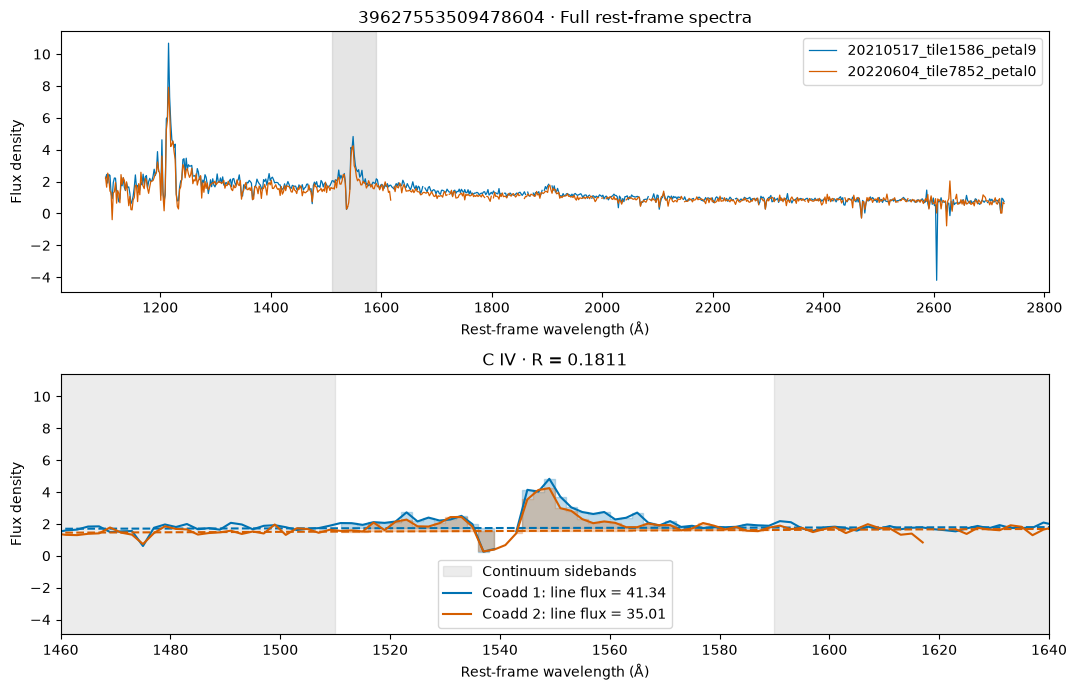

R = 41.3433 / 35.0054 − 1 = 0.1811
Saved R: 0.1811


In [49]:
from pathlib import Path

from astropy.io import fits
from extinction import fitzpatrick99


def pixel_edges(wave):
    return np.r_[
        wave[0] - (wave[1] - wave[0]) / 2,
        (wave[:-1] + wave[1:]) / 2,
        wave[-1] + (wave[-1] - wave[-2]) / 2,
    ]


def rebin(wave, flux, ivar, mask, edges):
    native = pixel_edges(wave)
    valid = np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0) & (mask == 0)
    rebinned = np.full(len(edges) - 1, np.nan)
    variance = rebinned.copy()

    for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        first = max(0, np.searchsorted(native, lo, side="right") - 1)
        stop = min(len(wave), np.searchsorted(native, hi, side="left"))
        pixels = np.arange(first, stop)
        pixels = pixels[valid[pixels]]

        overlap = np.minimum(native[pixels + 1], hi) - np.maximum(native[pixels], lo)
        weight = overlap / (hi - lo)
        if np.isclose(weight.sum(), 1, rtol=0, atol=1e-8):
            rebinned[j] = np.sum(weight * flux[pixels])
            variance[j] = np.sum(weight**2 / ivar[pixels])

    return rebinned, variance


def read_coadd(path, tid, z, ebv, rv, edges):
    weighted_flux = np.zeros(len(edges) - 1)
    total_weight = np.zeros(len(edges) - 1)

    with fits.open(path) as hdul:
        row = np.flatnonzero(hdul["FIBERMAP"].data["TARGETID"] == int(tid)).item()
        bands = ("BRZ",) if "BRZ_FLUX" in hdul else ("B", "R", "Z")

        for band in bands:
            wave = np.ascontiguousarray(hdul[f"{band}_WAVELENGTH"].data, dtype=float)
            flux = hdul[f"{band}_FLUX"].data[row].astype(float)
            ivar = hdul[f"{band}_IVAR"].data[row].astype(float)
            mask = hdul[f"{band}_MASK"].data[row]

            dust = 10 ** (0.4 * fitzpatrick99(wave, rv * ebv, r_v=rv, unit="aa"))
            f, v = rebin(wave / (1 + z), flux * dust, ivar / dust**2, mask, edges)
            good = np.isfinite(f) & np.isfinite(v) & (v > 0)
            weighted_flux[good] += f[good] / v[good]
            total_weight[good] += 1 / v[good]

    good = total_weight > 0
    flux = np.full(len(total_weight), np.nan)
    variance = flux.copy()
    flux[good] = weighted_flux[good] / total_weight[good]
    variance[good] = 1 / total_weight[good]
    return flux, variance


def measure_civ(wave, flux, variance, good):
    # Fit a straight continuum in the two sidebands.
    sidebands = good & (
        ((wave >= 1460) & (wave < 1510))
        | ((wave > 1590) & (wave <= 1640))
    )
    x = (wave - 1550) / 100
    design = np.column_stack([np.ones(len(wave)), x])
    sigma = np.sqrt(variance[sidebands])
    coefficients = np.linalg.lstsq(
        design[sidebands] / sigma[:, None], flux[sidebands] / sigma, rcond=None
    )[0]
    continuum = design @ coefficients

    # Subtract the continuum and sum the residual times the in-window width.
    edges = pixel_edges(wave)
    widths = np.maximum(0, np.minimum(edges[1:], 1590) - np.maximum(edges[:-1], 1510))
    line = good & (wave >= 1510) & (wave <= 1590) & (widths > 0)
    integrated_flux = np.sum((flux[line] - continuum[line]) * widths[line])
    return integrated_flux, continuum, line


example = ratio_ready.loc[ratio_ready["LINE"].eq("CIV")].iloc[0]
tid = str(example["TARGETID"])

step = settings["rest_bin_width"]
n_bins = round((settings["rest_max"] - settings["rest_min"]) / step)
edges = settings["rest_min"] + np.arange(n_bins + 1) * step
wave = (edges[:-1] + edges[1:]) / 2

spectra = []
for i in (1, 2):
    night = int(example[f"NIGHT{i}"])
    tile = int(example[f"TILE{i}"])
    petal = int(example[f"PETAL{i}"])
    path = coadd_dir / tid / f"coadd-{petal}-{tile}-{night}-{tid}.fits"
    print(path, "| exists:", path.is_file())
    spectra.append(read_coadd(
        path, tid, example["Z_USED"], example["EBV_GAL"], example["RV_GAL"], edges
    ))

good = np.logical_and.reduce([
    np.isfinite(f) & np.isfinite(v) & (v > 0) for f, v in spectra
])

fig, (full, zoom) = plt.subplots(2, 1, figsize=(11, 7))
full.axvspan(1510, 1590, color="gray", alpha=0.2)
zoom.axvspan(1460, 1510, color="gray", alpha=0.15, label="Continuum sidebands")
zoom.axvspan(1590, 1640, color="gray", alpha=0.15)

line_fluxes = []
for i, ((flux, var), color) in enumerate(zip(spectra, ["#0072B2", "#D55E00"]), 1):
    line_flux, continuum, line = measure_civ(wave, flux, var, good)
    line_fluxes.append(line_flux)

    full.plot(wave, flux, color=color, lw=0.9, label=example[f"OBS{i}"])
    zoom.plot(wave, flux, color=color, label=f"Coadd {i}: line flux = {line_flux:.2f}")
    zoom.plot(wave, continuum, "--", color=color)
    zoom.fill_between(wave, continuum, flux, where=line, step="mid", color=color, alpha=0.25)

dim, bright = sorted(line_fluxes)
R = bright / dim - 1 if dim > 0 else np.nan

full.set_title(f"{tid} · Full rest-frame spectra")
zoom.set(xlim=(1460, 1640), title=f"C IV · R = {R:.4f}")
for ax in (full, zoom):
    ax.set(xlabel="Rest-frame wavelength (Å)", ylabel="Flux density")
    ax.legend()
fig.tight_layout()
plt.show()

print(f"R = {bright:.4f} / {dim:.4f} − 1 = {R:.4f}")
print(f"Saved R: {example['R']:.4f}")

### 12. Final Nσ candidates

In [ ]:
line_hits = read_csv(NSIGMA_DIR / "line_hits.csv")
hit_keys = pair_keys + ["LINE"]
assert set(dim_pass[hit_keys].itertuples(index=False, name=None)) == set(
    line_hits[hit_keys].itertuples(index=False, name=None)
), "The audit flags and saved line hits disagree."
ns_step("Overall Nσ run", target_summary, line_hits)
display(line_hits.groupby("LINE")["TARGETID"].nunique().rename("Targets per line"))

Overall Nσ run | targets: 11,997 → 26 (11,971 removed)


LINE
CIII_1909          5
CIV                4
Lyalpha            3
MgII               5
SiIV_OIV_blend    10
Name: Targets per line, dtype: int64

In [ ]:
# Change the label to see the first 10 target IDs lost at that step.
display(removed_targets["ZWARN = 0"][:10])
display(ns_losses["At least one line × pair above the Nσ threshold"][:10])

Index(['39628473202905021', '39628478454174522', '39628514831368530',
       '39628530245435964', '39628525132579383', '39628530237050948',
       '39628509701734757', '39628509714319481', '39628509701734873',
       '39628499358585119'],
      dtype='string', name='TARGETID')

Index(['39627559461195064', '39627577379260157', '39627589333025596',
       '39627583368725742', '39627595314103869', '39627595314107372',
       '39627595397994168', '39627607297230788', '39627607519531644',
       '39627607381118795'],
      dtype='string', name='TARGETID')